# Bandit über die Modelle: explorative Architekturprüfung

**Einordnung:** explorative Architekturprüfung, kein Modellkandidat nach Standardablauf ([Issue #21](https://github.com/ibidreli/energy_price_prediction/issues/21)). Der vollständige Bericht steht in [`docs/exploration/bandit/README.md`](../docs/exploration/bandit/README.md).

**Frage:** Kann ein Bandit pro Viertelstunde das beste bestehende Modell laufend wählen und so `gbm_quantile` im Pinball Loss schlagen?

**Wichtig zum Lesen:** Die Testmonate waren ausgewertet, bevor Frage und Kriterium festgehalten wurden. Der Test ist also nicht blind. Der Holdout wurde nicht verwendet.

## Warum die Idee naheliegt

In einem Vortrag von CH Media ([Folien](../docs/exploration/bandit/slides/)) verteilt ein Bandit mit Thompson Sampling den Traffic live auf mehrere Empfehlungs-Blends. Unsere Modelle sind sich im Gesamtwert sehr ähnlich, je nach Uhrzeit gewinnt aber ein anderes. Darum die Frage, ob sich das laufend ausnutzen lässt.

## Warum die Architektur fraglich ist

| | CH Media | Dieses Projekt |
|---|---|---|
| **Rückmeldung** | nur vom ausgespielten Blend | von allen Modellen |
| **Tempo** | Neuverteilung alle 10 Minuten | eine Beobachtung pro Viertelstunde und Tag, erst nach rund zwei Tagen bekannt |

Ein Bandit löst das Problem, dass nur der gewählte Arm sichtbar ist. Hier sind alle Fehler sichtbar, Exploration bringt also keine zusätzliche Information.

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# The notebook runs from notebooks/; all paths are relative to the project root.
if Path.cwd().name == "notebooks":
    os.chdir("..")

RESULTS = Path("docs/exploration/bandit/results")
results = pd.read_csv(RESULTS / "test_results.csv", index_col="strategy")
persistence = pd.read_csv(RESULTS / "test_persistence.csv")
shares = pd.read_csv(RESULTS / "test_bandit_shares.csv")
tuning = pd.read_csv(RESULTS / "tune_selection.csv")

## Vorgehen

- **Arme:** Referenz, B1, B2 und Gradient Boosting aus dem gemeinsamen Backtest.
- **Keine Daten aus der Zukunft:** Jede Entscheidung für den Liefertag D nutzt nur Fehler bis D−2. Die Tests in `tests/test_bandit_exploration.py` prüfen das.
- **Einstellungen:** nur auf April und Mai gewählt (Tabelle unten), danach auf Juni bis August angewendet.
- **Abweichung vom Standardablauf:** eigener Ablauf mit täglicher Rückmeldung (`make bandit-exploration`), weil `make backtest` wöchentlich neu trainiert.
- **Kriterium:** Pinball Loss tiefer als `gbm_quantile`, und das 95-%-Intervall der täglichen Differenz liegt ganz unter 0.

In [2]:
tuning[tuning["chosen"]].drop(columns="chosen").reset_index(drop=True)

,strategy,eta,half_life,pinball
0,hedge_global,0.3,7.0,3.3077
1,hedge_hour,0.1,14.0,3.3094
2,hedge_slot,0.1,28.0,3.3079
3,follow_leader_slot,NaN,28.0,3.3428
4,thompson_bandit,NaN,inf,3.3863
5,thompson_bandit_no_floor,NaN,inf,3.3854
6,thompson_full_info,NaN,inf,3.3767


## Ergebnis auf Juni bis August

Die Spalte `kriterium_erfuellt` wird hier aus den Ergebnissen berechnet. Die beiden `HINDSIGHT`-Zeilen kennen die Zukunft und sind nur Obergrenzen. `cross_fit` wählt die Gewinner auf den jeweils anderen Testtagen. Alle drei sind keine echten Prognosen.

In [3]:
not_real = results.index.str.startswith(("HINDSIGHT", "cross_fit"))
table = results[["pinball", "vs_best_single_pct", "ci_low_ct", "ci_high_ct", "coverage_80", "mae_q50"]].copy()
table["kriterium_erfuellt"] = (results["ci_high_ct"] < 0).map({True: "ja", False: "nein"})
table.loc[not_real, "kriterium_erfuellt"] = "keine echte Prognose"
table.loc["gbm_quantile", "kriterium_erfuellt"] = "Massstab"
table.sort_values("pinball", ascending=False).round(4)

,pinball,vs_best_single_pct,ci_low_ct,ci_high_ct,coverage_80,mae_q50,kriterium_erfuellt
strategy,,,,,,,
B1,3.2510,2.7737,0.0479,0.1234,0.7274,9.9404,nein
B2,3.2254,1.9647,0.0330,0.1045,0.7360,9.8063,nein
thompson_bandit_no_floor,3.2066,1.3689,0.0302,0.0591,0.7395,9.8514,nein
thompson_bandit,3.2065,1.3673,0.0299,0.0586,0.7398,9.8548,nein
reference,3.2018,1.2165,-0.0113,0.0947,0.7521,9.9171,nein
thompson_full_info,3.2005,1.1764,0.0243,0.0524,0.7406,9.8384,nein
hour_winner_from_tune,3.1945,0.9873,0.0192,0.0530,0.7316,9.8052,nein
slot_winner_from_tune,3.1797,0.5192,0.0047,0.0310,0.7387,9.7873,nein
mean_all,3.1667,0.1064,-0.0105,0.0200,0.7569,9.7871,nein


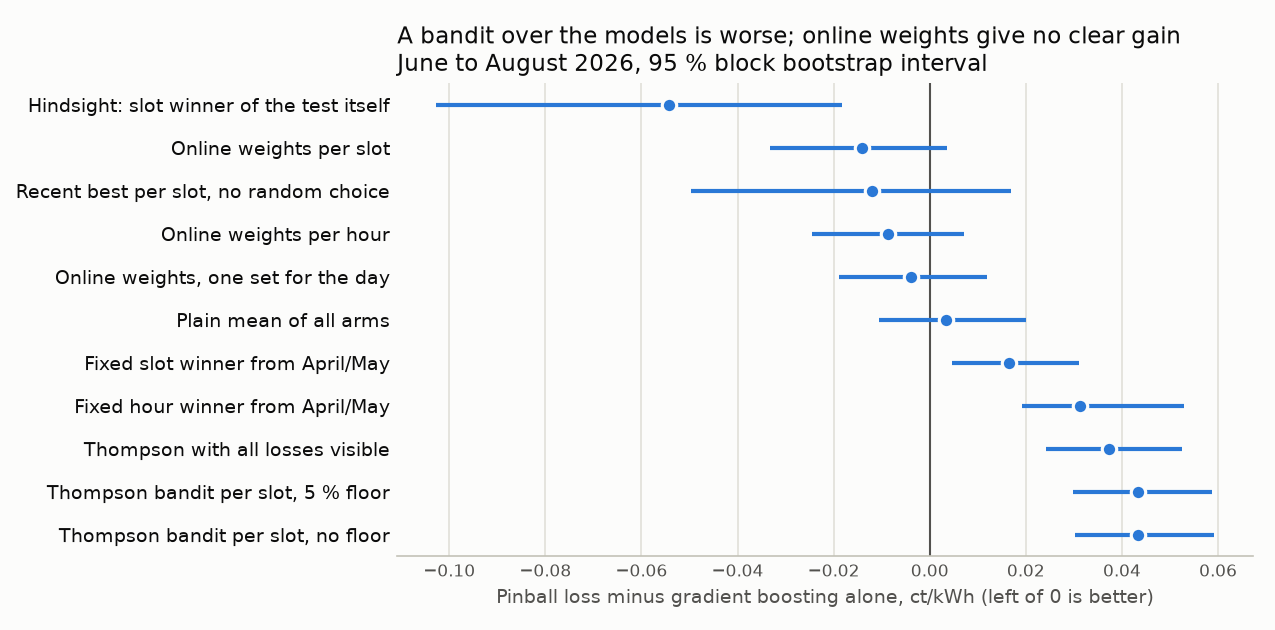

In [4]:
display(Image(RESULTS / "test_strategies.png"))

## Lernt der Bandit etwas?

Bei vier Modellen entspricht eine Gleichverteilung 25 % je Modell.

In [5]:
shares.assign(share_test=(100 * shares["share_test"]).round(1))

,arm,share_test
0,reference,24.7
1,B1,23.4
2,B2,25.8
3,gbm_quantile,26.1


## Sind die Gewinner pro Viertelstunde stabil?

Die Spalten zeigen, wie gut sich die Unterschiede zwischen zwei Modellen pro Viertelstunde von April/Mai auf den Test übertragen und wie viele Tage nötig wären, um den typischen Unterschied in einer einzelnen Viertelstunde sicher zu erkennen. Vorhanden sind 91 Testtage.

In [6]:
persistence.set_index("pair")[["spearman_slots_tune_test", "same_sign_slots_tune_test", "same_winner_slots_tune_test", "same_winner_slots_odd_even", "median_days_for_80pct_power"]].round(2)

,spearman_slots_tune_test,same_sign_slots_tune_test,same_winner_slots_tune_test,same_winner_slots_odd_even,median_days_for_80pct_power
pair,,,,,
gbm_quantile - reference,0.37,0.57,0.32,0.4,651.32
B2 - reference,0.47,0.60,0.32,0.4,326.35
gbm_quantile - B2,-0.01,0.48,0.32,0.4,542.95


## Entscheid

**Für dieses Problem ungeeignet, nicht weiterverfolgt.**

- Der Bandit wählt fast zufällig und liegt klar über `gbm_quantile`.
- Die laufenden Gewichte sind nicht signifikant besser, keines ihrer Intervalle liegt ganz unter 0.
- Die Gewinner pro Viertelstunde sind kaum stabil, das „perfekte Modell pro Slot“ ist überwiegend Rauschen.

**Grenzen:** Der Test ist nicht blind, deckt nur eine Saison ab und vergleicht ein Dutzend Strategien ohne Korrektur für Mehrfachtests. Der Vergleich mit den regulären Modellen ist nicht gleichwertig, weil diese Prüfung vom Standardablauf abweicht.

**Nachrechnen:** `make bandit-exploration STEP=tune`, dann `make bandit-exploration STEP=test`. Dieses Notebook liest nur die dabei geschriebenen CSV-Dateien.